# Generative tagging with Qwen3 — Part A · Evaluation

Loads the Part A adapter in vLLM and evaluates it with the answer constrained to the ten tags.

**Public Weights & Biases project:** [https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags](https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags)

**Adapter repository:** `rajatsxngh/qwen3-base-tag-adapter` (originally created as `hw5a-qwen3-base-tag-adapter`, the name that appears in the code and outputs below; Hugging Face redirects the old name)

Run this notebook in a **fresh Colab GPU runtime** (A100, L4, or RTX PRO 6000).
Use separate sessions for training and vLLM inference. Add `HF_TOKEN` (with
permission to write the two adapter repositories) and `WANDB_API_KEY` to
Colab Secrets and enable notebook access. Credentials are read without printing
them. The dataset is `multiclass_split.csv` (see `data/README.md`).

## Install the inference environment

Start with a fresh GPU runtime. Run training in its own notebook first;
this notebook loads the best saved adapter and never trains or tunes on test data.
Part B inference additionally requires Part A's saved evaluation results.

In [1]:
import subprocess, sys
# The inference environment follows lecture notebooks 4B and 7B.
# It must be separate from both TRL and Axolotl training environments.
packages = [
    "transformers==4.57.6", "datasets==5.0.0", "peft==0.19.1",
    "accelerate==1.14.0", "evaluate==0.4.6", "vllm==0.11.0",
    "wandb>=0.19.0", "scikit-learn", "matplotlib", "seaborn", "tabulate",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
print("Inference packages installed. If Colab requests a restart, restart now and continue at Configuration.")

Inference packages installed. If Colab requests a restart, restart now and continue at Configuration.


## Configuration

In [2]:
import os, json, hashlib, platform, time
from pathlib import Path
import numpy as np
import pandas as pd

PART = 'A'
PHASE = 'inference'
SEED = 42
HF_USERNAME = "rajatsxngh"
HF_REPO_ID = 'rajatsxngh/hw5a-qwen3-base-tag-adapter'
HF_PRIVATE = True  # W&B must be public; Hub adapters may remain private.
WANDB_ENTITY = "rajat-utd"
WANDB_PROJECT = "hw5_decoder_tags"
WANDB_PROJECT_URL = 'https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags'
BASE_MODEL = 'Qwen/Qwen3-1.7B-Base'
os.environ["WANDB_ENTITY"] = WANDB_ENTITY
os.environ["WANDB_PROJECT"] = WANDB_PROJECT
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(SEED)
print({"part": PART, "phase": PHASE, "base_model": BASE_MODEL,
       "adapter_repository": HF_REPO_ID, "wandb_project": WANDB_PROJECT_URL})

{'part': 'A', 'phase': 'inference', 'base_model': 'Qwen/Qwen3-1.7B-Base', 'adapter_repository': 'rajatsxngh/hw5a-qwen3-base-tag-adapter', 'wandb_project': 'https://forge.coreweave.com/wandb/rajat-utd/hw5_decoder_tags'}


## Authenticate using Colab Secrets

In [3]:
from google.colab import userdata
from huggingface_hub import login, HfApi
import wandb

def read_secret(name):
    try:
        value = userdata.get(name)
    except Exception:
        raise RuntimeError(
            f"Add {name} in Colab's Secrets panel and enable notebook access."
        ) from None
    if not value:
        raise RuntimeError(f"Colab Secret {name} is empty.")
    return value

os.environ["HF_TOKEN"] = read_secret("HF_TOKEN")
os.environ["WANDB_API_KEY"] = read_secret("WANDB_API_KEY")
login(token=os.environ["HF_TOKEN"], add_to_git_credential=False)
hf_api = HfApi(token=os.environ["HF_TOKEN"])
identity = hf_api.whoami()
assert identity["name"] == HF_USERNAME, "Sign in to the intended Hugging Face account."
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("Authenticated with Hugging Face and Weights & Biases.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rajat7 (rajat-utd) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Authenticated with Hugging Face and Weights & Biases.


## Load and validate the original data splits

In [5]:
from google.colab import drive, files
drive.mount("/content/drive")
WORK_DIR = Path("/content/drive/MyDrive/HW5_Decoder_Tags")
RESULTS_DIR = WORK_DIR / "results"
WORK_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = WORK_DIR / "multiclass_split.csv"
if not CSV_PATH.exists():
    print("Select the instructor's multiclass_split.csv. It will be saved to Drive for all four notebooks.")
    uploaded = files.upload()
    if "multiclass_split.csv" not in uploaded:
        raise FileNotFoundError("Upload the file named multiclass_split.csv.")
    CSV_PATH.write_bytes(uploaded["multiclass_split.csv"])
    del uploaded

DATASET_SHA256 = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
df = pd.read_csv(CSV_PATH)
required = {"id", "text", "tag", "label", "split", "decoder_train", "val_subset"}
assert required <= set(df.columns), f"Missing columns: {required - set(df.columns)}"
assert not df[["id", "text", "tag", "label", "split"]].isna().any().any()
assert df["id"].is_unique, "Question IDs must be unique."
assert df.groupby("label")["tag"].nunique().eq(1).all()
assert df.groupby("tag")["label"].nunique().eq(1).all()
class_names = df.drop_duplicates("label").sort_values("label")["tag"].tolist()
assert len(class_names) == 10
train_df = df.loc[df["decoder_train"].eq(1)].copy().reset_index(drop=True)
monitor_df = df.loc[df["val_subset"].eq(1)].copy().reset_index(drop=True)
val_df = df.loc[df["split"].eq("val")].copy().reset_index(drop=True)
test_df = df.loc[df["split"].eq("test")].copy().reset_index(drop=True)
assert (len(train_df), len(monitor_df), len(val_df), len(test_df)) == (5000, 1000, 6276, 6275)
assert train_df["split"].eq("train").all()
assert monitor_df["split"].eq("val").all()
assert set(train_df["id"]).isdisjoint(val_df["id"])
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert set(val_df["id"]).isdisjoint(test_df["id"])
assert set(monitor_df["id"]) <= set(val_df["id"])

# These exact functions are embedded identically in all four notebooks.
# Raw text is preserved; do not strip, clean, or add a trailing space.
def make_user_prompt(text):
    return f"Classify the TEXT by selecting one label from the following list: {class_names}. ### TEXT: {text}"

def make_base_prompt(text):
    return make_user_prompt(text) + " ### LABEL:"

print("Dataset:", CSV_PATH)
print("SHA-256:", DATASET_SHA256)
print("Classes:", class_names)
display(pd.DataFrame({"split": ["decoder_train", "val_subset", "validation", "test"],
                      "questions": [len(train_df), len(monitor_df), len(val_df), len(test_df)]}))

Mounted at /content/drive
Dataset: /content/drive/MyDrive/HW5_Decoder_Tags/multiclass_split.csv
SHA-256: 96782bf3e899d577e2c7cbfb23c31ac4f45397b23487697f75e8677d78633c3b
Classes: ['c#', 'java', 'php', 'javascript', 'android', 'jquery', 'c++', 'python', 'iphone', 'asp.net']


,split,questions
0,decoder_train,5000
1,val_subset,1000
2,validation,6276
3,test,6275


## GPU and inference libraries

In [6]:
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
import importlib.metadata
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from transformers import AutoTokenizer
from huggingface_hub import hf_hub_download, snapshot_download
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from vllm import LLM, SamplingParams
from vllm.lora.request import LoRARequest
from vllm.sampling_params import StructuredOutputsParams

assert torch.cuda.is_available(), "Select a fresh Colab GPU runtime before continuing."
assert torch.cuda.is_bf16_supported(), "Use an A100, L4, or RTX PRO 6000 runtime with BF16 support."
GPU_NAME = torch.cuda.get_device_name(0)
print("GPU:", GPU_NAME)
print({p: importlib.metadata.version(p) for p in ["torch", "transformers", "vllm", "peft", "wandb"]})

INFO 11-04 08:03:16 [__init__.py:216] Automatically detected platform cuda.
GPU: NVIDIA L4
{'torch': '2.8.0', 'transformers': '4.57.6', 'vllm': '0.11.0', 'peft': '0.19.1', 'wandb': '0.28.1'}


## Download and verify the exact best adapter

In [7]:
# Resolve a single immutable Hub commit before downloading any adapter files.
summary_name = f"training_summary_{PART}.json"
local_summary_path = RESULTS_DIR / summary_name
if local_summary_path.exists():
    training_summary = json.loads(local_summary_path.read_text())
    ADAPTER_REVISION = training_summary["adapter_revision"]
else:
    ADAPTER_REVISION = hf_api.model_info(HF_REPO_ID).sha
    summary_file = hf_hub_download(HF_REPO_ID, summary_name, revision=ADAPTER_REVISION)
    training_summary = json.loads(Path(summary_file).read_text())
    training_summary["adapter_revision"] = ADAPTER_REVISION

assert training_summary["part"] == PART
assert training_summary["base_model"] == BASE_MODEL
assert training_summary["adapter_repo_id"] == HF_REPO_ID
assert training_summary["dataset_sha256"] == DATASET_SHA256, "Training and inference must use the same CSV."
assert training_summary["class_names"] == class_names, "Tag ordering must match training."
assert training_summary["training_questions"] == 5000
assert training_summary["prompt_format"] == "hw5_single_tag_v1"
assert isinstance(ADAPTER_REVISION, str) and len(ADAPTER_REVISION) == 40

ADAPTER_DIR = Path(snapshot_download(HF_REPO_ID, revision=ADAPTER_REVISION))
hub_summary = json.loads((ADAPTER_DIR / summary_name).read_text())
for key in ["part", "base_model", "adapter_repo_id", "dataset_sha256", "class_names",
            "training_questions", "trainable_parameters", "training_time_seconds",
            "peak_gpu_memory_gb", "best_eval_loss", "prompt_format"]:
    assert hub_summary[key] == training_summary[key], f"Training metadata mismatch: {key}"
adapter_config = json.loads((ADAPTER_DIR / "adapter_config.json").read_text())
assert adapter_config["r"] == 128
assert adapter_config["peft_type"] == "LORA"
assert any((ADAPTER_DIR / name).exists() for name in ["adapter_model.safetensors", "adapter_model.bin"])

BASE_REVISION = training_summary.get("base_model_revision", training_summary.get("model_revision"))
assert isinstance(BASE_REVISION, str) and len(BASE_REVISION) == 40, "Training must record the base-model commit."
tokenizer = AutoTokenizer.from_pretrained(str(ADAPTER_DIR))
masking_path = ADAPTER_DIR / f"masking_{PART}.json"
masking_evidence = json.loads(masking_path.read_text())
print("Adapter:", HF_REPO_ID)
print("Adapter commit:", ADAPTER_REVISION)
print("Base-model commit:", BASE_REVISION)
display(pd.DataFrame([{
    "training_questions": training_summary["training_questions"],
    "trainable_parameters": training_summary["trainable_parameters"],
    "training_minutes": training_summary["training_time_seconds"] / 60,
    "peak_gpu_memory_GB": training_summary["peak_gpu_memory_gb"],
    "training_GPU": training_summary["gpu_name"],
    "best_validation_loss": training_summary["best_eval_loss"],
}]))

training_summary_A.json: 0.00B [00:00, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

added_tokens.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

masking_A.json: 0.00B [00:00, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

... (6 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

Adapter: rajatsxngh/hw5a-qwen3-base-tag-adapter
Adapter commit: e6830856e4882d402b245a972d3df87aac01f702
Base-model commit: ea980cb0a6c2ae4b936e82123acc929f1cec04c1


,training_questions,trainable_parameters,training_minutes,peak_gpu_memory_GB,training_GPU,best_validation_loss
0,5000,139460608,40.646595,11.140435,NVIDIA L4,0.063814


## Reproduce the training prompt exactly

In [8]:
def make_inference_prompt(text):
    return make_base_prompt(text)

assert make_inference_prompt(training_summary["prompt_example_text"]) == training_summary["prompt_example"]
assert not make_inference_prompt(training_summary["prompt_example_text"]).endswith(" ")
choices = [" " + tag for tag in class_names]

# Question 1: preserve actual token IDs and token strings, including the space.
tokenization_example = {}
for spelling in [" javascript", "javascript"]:
    ids = tokenizer.encode(spelling, add_special_tokens=False)
    tokenization_example[spelling] = {"ids": ids, "tokens": tokenizer.convert_ids_to_tokens(ids)}
    print(repr(spelling), "->", ids, "->", tokenizer.convert_ids_to_tokens(ids))
assert tokenization_example[" javascript"]["ids"] != tokenization_example["javascript"]["ids"]

' javascript' -> [35710] -> ['Ġjavascript']
'javascript' -> [14073] -> ['javascript']


## Start vLLM and W&B logging

In [9]:
FREE_MAX_TOKENS = 64
CONSTRAINED_MAX_TOKENS = max(16, max(len(tokenizer.encode(c, add_special_tokens=False)) for c in choices) + 4)
MAX_MODEL_LEN = 1024

def encode_frame(frame):
    prompts = [make_inference_prompt(t) for t in frame["text"]]
    ids = tokenizer(prompts, add_special_tokens=False, truncation=False)["input_ids"]
    assert max(map(len, ids)) + FREE_MAX_TOKENS <= MAX_MODEL_LEN, "Do not silently truncate a prompt."
    # Explicit token IDs prevent the inference engine from inserting extra special tokens.
    return [{"prompt_token_ids": tokens} for tokens in ids], max(map(len, ids))

val_inputs, val_max_length = encode_frame(val_df)
test_inputs, test_max_length = encode_frame(test_df)
monitor_inputs, monitor_max_length = encode_frame(monitor_df)
print("Longest prompt lengths:", {"validation": val_max_length, "test": test_max_length,
                                 "monitoring": monitor_max_length})
print("Example prompt (repr preserves all whitespace):")
print(repr(make_inference_prompt(val_df.iloc[0]["text"])))
print("Allowed completions:", choices)

llm = LLM(
    model=BASE_MODEL,
    revision=BASE_REVISION,
    tokenizer=str(ADAPTER_DIR),
    dtype="bfloat16",
    enable_lora=True,
    max_lora_rank=128,
    max_loras=1,
    max_model_len=MAX_MODEL_LEN,
    max_num_seqs=64,
    gpu_memory_utilization=0.65,
    enable_chunked_prefill=False,
    seed=SEED,
)
lora_request = LoRARequest(f"hw5{PART.lower()}_tag_adapter", 1, str(ADAPTER_DIR))
constrained_params = SamplingParams(
    temperature=0, seed=SEED, max_tokens=CONSTRAINED_MAX_TOKENS,
    structured_outputs=StructuredOutputsParams(choice=choices),
)
free_params = SamplingParams(temperature=0, seed=SEED, max_tokens=FREE_MAX_TOKENS)

run = wandb.init(
    entity=WANDB_ENTITY, project=WANDB_PROJECT,
    name=f"hw5{PART.lower()}_inference", job_type="evaluation",
    config={"part": PART, "base_model": BASE_MODEL, "base_revision": BASE_REVISION,
            "adapter_repository": HF_REPO_ID, "adapter_revision": ADAPTER_REVISION,
            "dataset_sha256": DATASET_SHA256, "seed": SEED,
            "validation_questions": len(val_df), "test_questions": len(test_df),
            "free_answer_questions": len(monitor_df), "temperature": 0,
            "constrained_max_tokens": CONSTRAINED_MAX_TOKENS, "free_max_tokens": FREE_MAX_TOKENS,
            "class_names": class_names, "gpu": GPU_NAME},
)
print("W&B evaluation run:", run.url)

Longest prompt lengths: {'validation': 590, 'test': 897, 'monitoring': 490}
Example prompt (repr preserves all whitespace):
'Classify the TEXT by selecting one label from the following list: [\'c#\', \'java\', \'php\', \'javascript\', \'android\', \'jquery\', \'c++\', \'python\', \'iphone\', \'asp.net\']. ### TEXT: Conflicting event-handling in jQuery <p>I have a <code>&lt;div&gt;</code> like this:</p>\n\n<pre><code>&lt;div id="Field1"&gt;\n  &lt;label id="label1"&gt;Name&lt;/label&gt;&lt;br/&gt;\n  &lt;input type="text" data-attr="text" style="..." id="input1"/&gt;&lt;br/&gt;\n  &lt;label id="instr1"/&gt;\n  &lt;div class="xfb-row-options1"&gt;\n    &lt;a class="button-delete" src="..." style="..."&gt;-&lt;/a&gt; \n  &lt;/div&gt;\n&lt;/div&gt;\n</code></pre>\n\n<p>I already have a jQuery function:</p>\n\n<pre><code>$("#fb_contentarea_col1down21 div").live("click", function(){\n  // some stuff to change the properties of the Field,\n  // like changing the field name, size.\n  return fa

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

INFO 11-04 08:05:36 [model.py:547] Resolved architecture: Qwen3ForCausalLM


`torch_dtype` is deprecated! Use `dtype` instead!


INFO 11-04 08:05:36 [model.py:1510] Using max model len 1024
INFO 11-04 08:05:37 [scheduler.py:205] Chunked prefill is enabled with max_num_batched_tokens=8192.
WARNING 11-04 08:05:37 [lora.py:92] `lora_extra_vocab_size` is deprecated and will be removed in v0.12.0. Additional vocabulary support for LoRA adapters is being phased out.


generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

INFO 11-04 08:08:06 [llm.py:306] Supported_tasks: ['generate']


wandb: Detected [openai] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai


W&B evaluation run: https://wandb.ai/rajat-utd/hw5_decoder_tags/runs/f9tpyan9


## Evaluation helpers

In [10]:
def generate_rows(frame, inputs, params, adapter, label, constrained):
    start = time.perf_counter()
    outputs = llm.generate(inputs, sampling_params=params, lora_request=adapter, use_tqdm=True)
    elapsed = time.perf_counter() - start
    assert len(outputs) == len(frame)
    rows = []
    for source, request, output in zip(frame.itertuples(index=False), inputs, outputs):
        assert list(output.prompt_token_ids) == request["prompt_token_ids"], "Prompt order/tokenization changed."
        answer = output.outputs[0]
        raw = answer.text
        # Remove only surrounding whitespace; no case folding, tag extraction,
        # punctuation removal, JSON parsing, or removal of reasoning text.
        prediction = raw.strip()
        valid = prediction in class_names
        truncated = answer.finish_reason == "length"
        if constrained:
            assert raw in choices, f"Constrained output outside exact choices: {raw!r}"
            assert valid and not truncated, "Constrained generation did not finish with a complete allowed label."
        rows.append({"id": source.id, "true_tag": source.tag,
                     "raw_response": raw, "prediction": prediction,
                     "valid_tag": valid, "raw_exact_tag": raw in class_names,
                     "finish_reason": answer.finish_reason,
                     "generated_tokens": len(answer.token_ids), "truncated": truncated})
    predictions = pd.DataFrame(rows)
    dest = RESULTS_DIR / f"hw5{PART}_{label}.csv"
    predictions.to_csv(dest, index=False)
    print(f"{label}: {len(predictions):,} questions in {elapsed:.1f} seconds; saved {dest.name}")
    return predictions, elapsed

def score(predictions):
    assert predictions["valid_tag"].all()
    return {"accuracy": float(accuracy_score(predictions["true_tag"], predictions["prediction"])),
            "macro_f1": float(f1_score(predictions["true_tag"], predictions["prediction"],
                                        labels=class_names, average="macro", zero_division=0))}

def log_predictions(label, predictions):
    # The saved outputs and W&B table contain IDs, targets, and predictions, not question bodies.
    run.log({label: wandb.Table(dataframe=predictions)})

def plot_confusion(predictions, label):
    cm = confusion_matrix(predictions["true_tag"], predictions["prediction"], labels=class_names)
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set(xlabel="Predicted tag", ylabel="True tag", title=f"HW5{PART} {label} confusion matrix")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"hw5{PART}_{label}_confusion_matrix.png", dpi=160, bbox_inches="tight")
    run.log({f"{label}/confusion_matrix": wandb.Image(fig)})
    display(fig)
    plt.close(fig)
    return cm

def ranked_confusions(cm, limit=5):
    items = [{"true_tag": class_names[i], "predicted_tag": class_names[j], "count": int(cm[i,j])}
             for i in range(len(class_names)) for j in range(len(class_names)) if i != j and cm[i,j] > 0]
    return sorted(items, key=lambda r: (-r["count"], r["true_tag"], r["predicted_tag"]))[:limit]

## Fine-tuned model: full validation and test splits

Adding requests:   0%|          | 0/6276 [00:00<?, ?it/s]

WARNING 11-04 08:13:20 [processor.py:215] vLLM has deprecated support for supporting different tokenizers for different LoRAs. By default, vLLM uses base model's tokenizer. If you are using a LoRA with its own tokenizer, consider specifying `--tokenizer [lora_path]` to use the LoRA tokenizer.


Processed prompts:   0%|          | 0/6276 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

validation_constrained: 6,276 questions in 100.2 seconds; saved hw5A_validation_constrained.csv


Adding requests:   0%|          | 0/6275 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/6275 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

test_constrained: 6,275 questions in 96.9 seconds; saved hw5A_test_constrained.csv


,split,questions,accuracy,macro_f1
0,validation,6276,0.954589,0.948848
1,test,6275,0.953944,0.949779


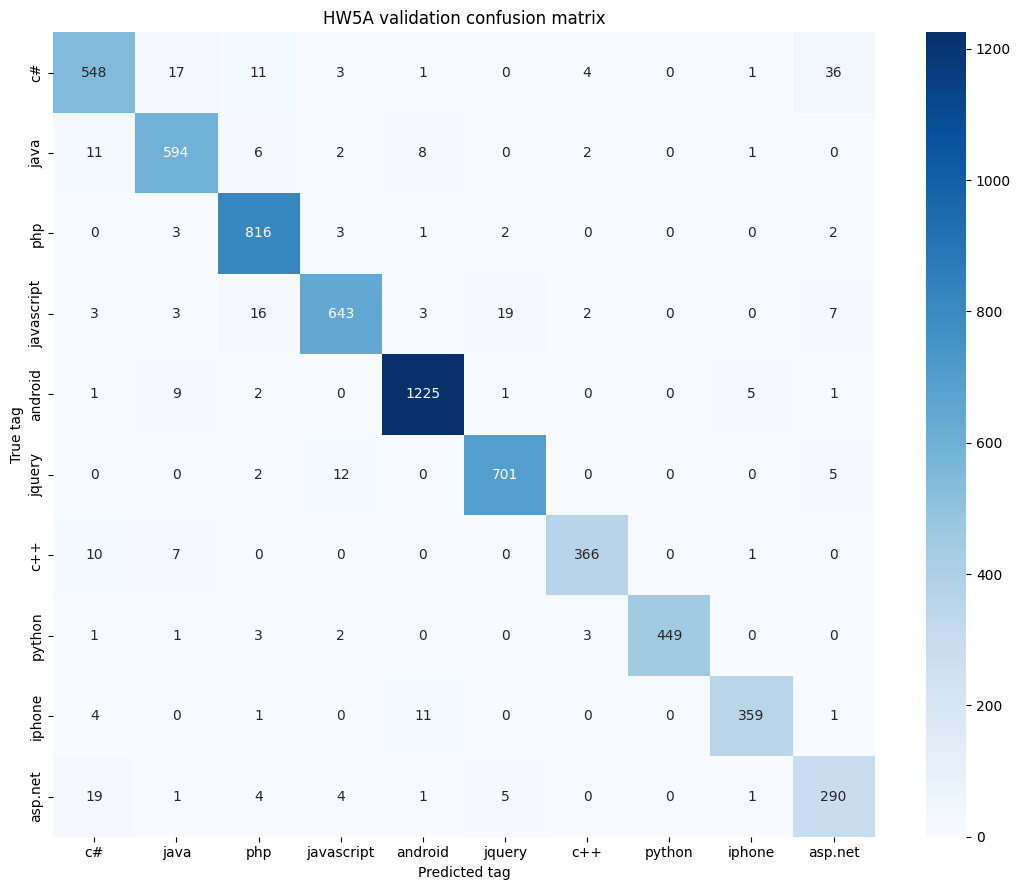

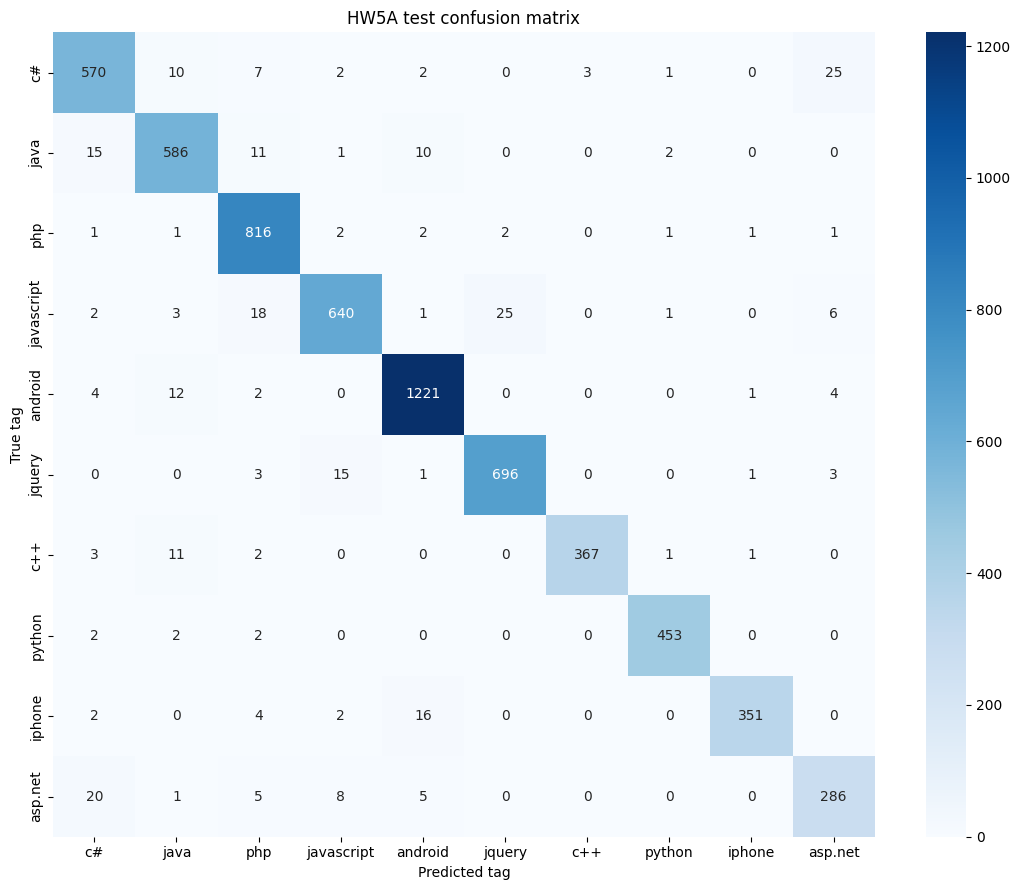

              precision    recall  f1-score   support

          c#     0.9208    0.9194    0.9201       620
        java     0.9361    0.9376    0.9369       625
         php     0.9379    0.9867    0.9617       827
  javascript     0.9552    0.9195    0.9370       696
     android     0.9706    0.9815    0.9760      1244
      jquery     0.9627    0.9680    0.9653       719
         c++     0.9919    0.9532    0.9722       385
      python     0.9869    0.9869    0.9869       459
      iphone     0.9887    0.9360    0.9616       375
     asp.net     0.8800    0.8800    0.8800       325

    accuracy                         0.9539      6275
   macro avg     0.9531    0.9469    0.9498      6275
weighted avg     0.9542    0.9539    0.9539      6275



,precision,recall,f1-score,support
c#,0.920840,0.919355,0.920097,620.000000
java,0.936102,0.937600,0.936851,625.000000
php,0.937931,0.986699,0.961697,827.000000
javascript,0.955224,0.919540,0.937042,696.000000
android,0.970588,0.981511,0.976019,1244.000000
jquery,0.962656,0.968011,0.965326,719.000000
c++,0.991892,0.953247,0.972185,385.000000
python,0.986928,0.986928,0.986928,459.000000
iphone,0.988732,0.936000,0.961644,375.000000
asp.net,0.880000,0.880000,0.880000,325.000000


,true_tag,predicted_tag,count
0,c#,asp.net,25
1,javascript,jquery,25
2,asp.net,c#,20
3,javascript,php,18
4,iphone,android,16


In [11]:
# Each fine-tuned split is generated exactly once. All later tables/plots reuse these predictions.
validation_predictions, validation_seconds = generate_rows(
    val_df, val_inputs, constrained_params, lora_request, "validation_constrained", True)
test_predictions, test_seconds = generate_rows(
    test_df, test_inputs, constrained_params, lora_request, "test_constrained", True)
validation_metrics = score(validation_predictions)
test_metrics = score(test_predictions)
display(pd.DataFrame([{"split": "validation", "questions": len(val_df), **validation_metrics},
                      {"split": "test", "questions": len(test_df), **test_metrics}]))
run.log({"validation/accuracy": validation_metrics["accuracy"],
         "validation/macro_f1": validation_metrics["macro_f1"],
         "test/accuracy": test_metrics["accuracy"], "test/macro_f1": test_metrics["macro_f1"]})
log_predictions("validation/predictions", validation_predictions)
log_predictions("test/predictions", test_predictions)
validation_cm = plot_confusion(validation_predictions, "validation")
test_cm = plot_confusion(test_predictions, "test")
print(classification_report(test_predictions["true_tag"], test_predictions["prediction"],
                            labels=class_names, target_names=class_names, digits=4, zero_division=0))
report = classification_report(test_predictions["true_tag"], test_predictions["prediction"],
                               labels=class_names, target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv(RESULTS_DIR / f"hw5{PART}_test_classification_report.csv")
run.log({"test/classification_report": wandb.Table(dataframe=report_df.reset_index(names="tag"))})
top_confusions = ranked_confusions(test_cm)
display(pd.DataFrame(top_confusions))

## Experiment 1: constrained validation without the adapter

In [12]:
# The same base/instruction checkpoint without the learned LoRA adapter.
# The prompt, tokenizer, tag constraint, and decoding settings are unchanged.
untrained_validation_predictions, untrained_validation_seconds = generate_rows(
    val_df, val_inputs, constrained_params, None, "untrained_validation_constrained", True)
untrained_validation_metrics = score(untrained_validation_predictions)
display(pd.DataFrame([
    {"model": "untrained", **untrained_validation_metrics},
    {"model": "fine-tuned", **validation_metrics},
]))
run.log({"untrained_validation/accuracy": untrained_validation_metrics["accuracy"],
         "untrained_validation/macro_f1": untrained_validation_metrics["macro_f1"],
         "validation/macro_f1_gain": validation_metrics["macro_f1"] - untrained_validation_metrics["macro_f1"]})
log_predictions("untrained_validation/predictions", untrained_validation_predictions)

Adding requests:   0%|          | 0/6276 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/6276 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

untrained_validation_constrained: 6,276 questions in 66.5 seconds; saved hw5A_untrained_validation_constrained.csv


,model,accuracy,macro_f1
0,untrained,0.767049,0.745430
1,fine-tuned,0.954589,0.948848


## Experiment 2: free answers on the same 1,000 monitoring questions

Both models receive the same prompts, greedy decoding, and a 64-token limit.
**Raw exact-match invalid counts** require the entire answer to equal a tag name,
with no normalization; even Part A's deliberately trained leading space fails
this literal check. **Normalized invalid counts** separately remove only outer
whitespace before checking tag membership. Neither check extracts a tag from an
explanation. Raw answers and both counts are saved; length-limited responses
are also reported separately.

In [13]:
untrained_free, untrained_free_seconds = generate_rows(
    monitor_df, monitor_inputs, free_params, None, "untrained_monitor_free", False)
finetuned_free, finetuned_free_seconds = generate_rows(
    monitor_df, monitor_inputs, free_params, lora_request, "finetuned_monitor_free", False)
untrained_invalid_count = int((~untrained_free["valid_tag"]).sum())
finetuned_invalid_count = int((~finetuned_free["valid_tag"]).sum())
untrained_raw_exact_invalid_count = int((~untrained_free["raw_exact_tag"]).sum())
finetuned_raw_exact_invalid_count = int((~finetuned_free["raw_exact_tag"]).sum())
free_counts = pd.DataFrame([
    {"model": name, "questions": len(frame), "normalized_invalid_answers": int((~frame["valid_tag"]).sum()),
     "normalized_invalid_percent": 100 * (~frame["valid_tag"]).mean(),
     "raw_exact_tag_failures": int((~frame["raw_exact_tag"]).sum()),
     "length_limited_answers": int(frame["truncated"].sum())}
    for name, frame in [("untrained", untrained_free), ("fine-tuned", finetuned_free)]
])
display(free_counts)
for name, frame in [("untrained", untrained_free), ("fine-tuned", finetuned_free)]:
    print(f"Examples of raw exact-match failures for {name} (no whitespace normalization):")
    display(frame.loc[~frame["raw_exact_tag"], ["id", "true_tag", "raw_response", "valid_tag", "finish_reason"]].head(10))
    log_predictions(f"free_answers/{name}", frame)
    run.log({f"free_answers/{name}_invalid_count": int((~frame["valid_tag"]).sum()),
             f"free_answers/{name}_normalized_invalid_count": int((~frame["valid_tag"]).sum()),
             f"free_answers/{name}_raw_exact_invalid_count": int((~frame["raw_exact_tag"]).sum()),
             f"free_answers/{name}_truncated_count": int(frame["truncated"].sum())})
run.log({"free_answers/counts": wandb.Table(dataframe=free_counts)})

Adding requests:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1000 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

untrained_monitor_free: 1,000 questions in 13.5 seconds; saved hw5A_untrained_monitor_free.csv


Adding requests:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed prompts:   0%|          | 0/1000 [00:00<?, ?it/s, est. speed input: 0.00 toks/s, output: 0.00 toks/s…

finetuned_monitor_free: 1,000 questions in 15.7 seconds; saved hw5A_finetuned_monitor_free.csv


,model,questions,normalized_invalid_answers,normalized_invalid_percent,raw_exact_tag_failures,length_limited_answers
0,untrained,1000,166,16.6,1000,94
1,fine-tuned,1000,0,0.0,1000,0


Examples of raw exact-match failures for untrained (no whitespace normalization):


,id,true_tag,raw_response,valid_tag,finish_reason
0,15478,javascript,javascript,True,stop
1,49159,asp.net,'asp.net',False,stop
2,49460,c#,c#,True,stop
3,50530,python,c#,True,stop
4,54856,jquery,c#,True,stop
5,57062,jquery,jquery,True,stop
6,59692,jquery,javascript,True,stop
7,59984,c#,c#,True,stop
8,60965,android,android,True,stop
9,63068,java,java,True,stop


Examples of raw exact-match failures for fine-tuned (no whitespace normalization):


,id,true_tag,raw_response,valid_tag,finish_reason
0,15478,javascript,javascript,True,stop
1,49159,asp.net,asp.net,True,stop
2,49460,c#,java,True,stop
3,50530,python,python,True,stop
4,54856,jquery,jquery,True,stop
5,57062,jquery,jquery,True,stop
6,59692,jquery,jquery,True,stop
7,59984,c#,c#,True,stop
8,60965,android,android,True,stop
9,63068,java,java,True,stop


## Save the measured results

In [14]:
evaluation_summary = {
    "part": PART, "base_model": BASE_MODEL, "base_model_revision": BASE_REVISION,
    "adapter_repo_id": HF_REPO_ID, "adapter_revision": ADAPTER_REVISION,
    "dataset_sha256": DATASET_SHA256, "class_names": class_names,
    "validation_questions": len(val_df), "test_questions": len(test_df), "monitoring_questions": len(monitor_df),
    "validation_accuracy": validation_metrics["accuracy"], "validation_macro_f1": validation_metrics["macro_f1"],
    "test_accuracy": test_metrics["accuracy"], "test_macro_f1": test_metrics["macro_f1"],
    "untrained_validation_accuracy": untrained_validation_metrics["accuracy"],
    "untrained_validation_macro_f1": untrained_validation_metrics["macro_f1"],
    "untrained_invalid_count": untrained_invalid_count,
    "finetuned_invalid_count": finetuned_invalid_count,
    "untrained_normalized_invalid_count": untrained_invalid_count,
    "finetuned_normalized_invalid_count": finetuned_invalid_count,
    "untrained_raw_exact_invalid_count": untrained_raw_exact_invalid_count,
    "finetuned_raw_exact_invalid_count": finetuned_raw_exact_invalid_count,
    "untrained_truncated_count": int(untrained_free["truncated"].sum()),
    "finetuned_truncated_count": int(finetuned_free["truncated"].sum()),
    "invalid_answer_definition": "raw_response.strip() not in class_names; no other normalization",
    "normalized_invalid_answer_definition": "raw_response.strip() not in class_names; only outer whitespace is removed",
    "raw_exact_invalid_answer_definition": "raw_response not in class_names; no normalization, including whitespace",
    "legacy_invalid_count_note": "untrained_invalid_count and finetuned_invalid_count alias the normalized counts",
    "free_max_tokens": FREE_MAX_TOKENS, "constrained_max_tokens": CONSTRAINED_MAX_TOKENS,
    "top_confusions": top_confusions, "tokenization_example": tokenization_example,
    "gpu_name": GPU_NAME, "wandb_run_url": run.url,
    "inference_seconds": {"validation": validation_seconds, "test": test_seconds,
                          "untrained_validation": untrained_validation_seconds,
                          "untrained_free": untrained_free_seconds, "finetuned_free": finetuned_free_seconds},
}
summary_path = RESULTS_DIR / f"evaluation_summary_{PART}.json"
summary_path.write_text(json.dumps(evaluation_summary, indent=2))
run.summary.update({k: v for k, v in evaluation_summary.items()
                    if isinstance(v, (int, float, str, bool))})
print("Saved actual evaluation results to", summary_path)

Saved actual evaluation results to /content/drive/MyDrive/HW5_Decoder_Tags/results/evaluation_summary_A.json


In [15]:
HW4_ROWS = [{'model': 'HW4A ModernBERT classification head', 'training_questions': 29287, 'trainable_parameters': 149612554, 'training_time_seconds': 491.99999999999994, 'peak_gpu_memory_gb': 7.05, 'validation_macro_f1': 0.9326416716, 'test_macro_f1': 0.9222282219}, {'model': 'HW4B Qwen3 base classification head', 'training_questions': 5000, 'trainable_parameters': 139481088, 'training_time_seconds': 1056.0, 'peak_gpu_memory_gb': 4.66, 'validation_macro_f1': 0.9456519408, 'test_macro_f1': 0.9412107298, 'test_accuracy': 0.9464541833}]

## Generate the Part A analysis from this run

In [16]:
hw4_qwen = HW4_ROWS[1]
confusion_text = "; ".join(f"{r['true_tag']} → {r['predicted_tag']} ({r['count']})" for r in top_confusions[:3]) or "none"
change_verb = "increased" if validation_metrics["macro_f1"] >= untrained_validation_metrics["macro_f1"] else "decreased"
analysis_text = (
    f"Part A achieved test macro-F1 {test_metrics['macro_f1']:.4f} and accuracy {test_metrics['accuracy']:.4f}. "
    f"Compared with HW4 Part B's classification head (macro-F1 {hw4_qwen['test_macro_f1']:.4f}, "
    f"accuracy {hw4_qwen['test_accuracy']:.4f}), the language head changed test macro-F1 by "
    f"{100 * (test_metrics['macro_f1'] - hw4_qwen['test_macro_f1']):+.2f} percentage points using the same 5,000 training questions. "
    f"The untrained base model obtained validation macro-F1 {untrained_validation_metrics['macro_f1']:.4f} with the tag list and constraint, "
    f"while fine-tuning {change_verb} it to {validation_metrics['macro_f1']:.4f}, a change of "
    f"{100 * (validation_metrics['macro_f1'] - untrained_validation_metrics['macro_f1']):+.2f} percentage points. "
    f"The largest remaining directed test confusions were {confusion_text}. "
    f"Without the constraint, raw exact-match invalid counts were {untrained_raw_exact_invalid_count}/1,000 untrained and "
    f"{finetuned_raw_exact_invalid_count}/1,000 fine-tuned (any extra whitespace, including Part A's trained leading space, fails this literal check), "
    f"whereas removing only outer whitespace yielded normalized invalid counts of {untrained_invalid_count}/1,000 and "
    f"{finetuned_invalid_count}/1,000; {int(untrained_free['truncated'].sum())} and "
    f"{int(finetuned_free['truncated'].sum())} answers, respectively, reached the {FREE_MAX_TOKENS}-token limit."
)
display(Markdown(analysis_text))
(RESULTS_DIR / "analysis_A.md").write_text(analysis_text)

Part A achieved test macro-F1 0.9498 and accuracy 0.9539. Compared with HW4 Part B's classification head (macro-F1 0.9412, accuracy 0.9465), the language head changed test macro-F1 by +0.86 percentage points using the same 5,000 training questions. The untrained base model obtained validation macro-F1 0.7454 with the tag list and constraint, while fine-tuning increased it to 0.9488, a change of +20.34 percentage points. The largest remaining directed test confusions were c# → asp.net (25); javascript → jquery (25); asp.net → c# (20). Without the constraint, raw exact-match invalid counts were 1000/1,000 untrained and 1000/1,000 fine-tuned (any extra whitespace, including Part A's trained leading space, fails this literal check), whereas removing only outer whitespace yielded normalized invalid counts of 166/1,000 and 0/1,000; 94 and 0 answers, respectively, reached the 64-token limit.

897

In [17]:
# Save plots, summaries, and predictions as an artifact; keep all notebook outputs visible.
artifact = wandb.Artifact(f"hw5{PART.lower()}-evaluation", type="evaluation")
for path in sorted(RESULTS_DIR.glob(f"hw5{PART}_*")):
    if path.is_file():
        artifact.add_file(str(path))
for name in [f"evaluation_summary_{PART}.json", f"analysis_{PART}.md"]:
    artifact.add_file(str(RESULTS_DIR / name))
if PART == "B":
    for name in ["hw4_hw5_comparison.csv", "comparison_table.md", "answers_B.md"]:
        artifact.add_file(str(RESULTS_DIR / name))
run.log_artifact(artifact)
print("Completed evaluation run:", run.url)
run.finish()
print("Save this notebook with its outputs. Fill the final markdown cells from the generated analysis files before submission.")

Completed evaluation run: https://wandb.ai/rajat-utd/hw5_decoder_tags/runs/f9tpyan9


free_answers/fine-tuned_invalid_count,▁
free_answers/fine-tuned_normalized_invalid_count,▁
free_answers/fine-tuned_raw_exact_invalid_count,▁
free_answers/fine-tuned_truncated_count,▁
free_answers/untrained_invalid_count,▁
free_answers/untrained_normalized_invalid_count,▁
free_answers/untrained_raw_exact_invalid_count,▁
free_answers/untrained_truncated_count,▁
test/accuracy,▁
test/macro_f1,▁
+5,...


Save this notebook with its outputs. Fill the final markdown cells from the generated analysis files before submission.


## Part A analysis

Part A reached a test macro-F1 of 0.9498 and an accuracy of 0.9539. That is 0.86 points higher in macro-F1 than the Qwen3 classification head from [part 1](https://github.com/rajatsxngh/modernbert-vs-qwen3-qlora) (0.9412 macro-F1, 0.9465 accuracy), which used the same Qwen3-1.7B-Base model and the same 5,000 training questions. Even without any training, the base model does reasonably well when the tag list is in the prompt and the answer is constrained: its validation macro-F1 is 0.7454, and fine-tuning raises it to 0.9488 (+20.3 points). Without the constraint, the untrained base model wrote something other than a tag on 166 of the 1,000 monitoring questions (94 of them ran to the 64-token limit), while the fine-tuned model gave a valid tag every time (0 of 1,000, after removing the leading space it was trained to write). The pairs still confused most often are c# and asp.net (25 c# questions predicted as asp.net and 20 the other way), javascript and jquery (25), javascript and php (18), and iphone and android (16).

## Sources and reproducibility

API references: [vLLM 0.11 structured outputs](https://docs.vllm.ai/en/v0.11.0/features/structured_outputs.html),
[vLLM 0.11 LoRA adapters](https://docs.vllm.ai/en/v0.11.0/features/lora.html),
and [Hugging Face snapshot downloads](https://huggingface.co/docs/huggingface_hub/guides/download).
Training selects the checkpoint using only monitoring loss. Validation and test predictions
are generated once per fine-tuned model and reused for every reported metric and plot.